<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 7: Perceptron and Forward Propagation

This notebook contains the complete implementation of a single-layer Perceptron from scratch using NumPy, showing its application to both a linearly separable problem (loan approval) and a non-linearly separable problem (XOR gate).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

## Task 1: Implement weighted sum, bias, and step activation in NumPy

In [2]:
def step_activation(z):
    """Step activation function (returns 1 for z >= 0, else 0)"""
    return np.where(z >= 0, 1, 0)

class Perceptron:
    def __init__(self, input_size, lr=0.1, epochs=100):
        self.lr = lr
        self.epochs = epochs
        # Initialize weights and bias randomly
        self.weights = np.random.randn(input_size) * 0.01
        self.bias = np.random.randn() * 0.01

    def forward(self, X):
        """Forward propagation: Weighted sum + Bias, then Step activation"""
        z = np.dot(X, self.weights) + self.bias
        return step_activation(z)

    def train(self, X, y):
        """Train using the perceptron learning rule"""
        weight_history = []
        bias_history = []
        errors_per_epoch = []

        for epoch in range(self.epochs):
            total_error = 0
            for xi, target in zip(X, y):
                prediction = self.forward(xi)
                error = target - prediction
                if error != 0:
                    # Update weight and bias
                    self.weights += self.lr * error * xi
                    self.bias += self.lr * error
                    total_error += abs(error)

            weight_history.append(self.weights.copy())
            bias_history.append(self.bias)
            errors_per_epoch.append(total_error)

            # Stop early if converged
            if total_error == 0:
                break

        return weight_history, bias_history, errors_per_epoch

## Task 2 & 3: Train on Loan Data and Plot Decision Boundary

In [3]:
# Generate synthetic loan data (100 past applications)
# Feature 1: Credit Score (scaled 0 to 1)
# Feature 2: Income-to-Debt Ratio (scaled 0 to 1)
X_loan = np.random.rand(100, 2)
# Linearly separable rule: Credit Score - Income-to-Debt Ratio > -0.1
y_loan = np.where(X_loan[:, 0] - X_loan[:, 1] > -0.1, 1, 0)

# Train the Perceptron
perceptron_loan = Perceptron(input_size=2, lr=0.1, epochs=50)
w_hist, b_hist, error_hist = perceptron_loan.train(X_loan, y_loan)

# Print final state
print(f"Training converged in {len(error_hist)} epochs.")
print(f"Final Weights: {perceptron_loan.weights}")
print(f"Final Bias: {perceptron_loan.bias}")

Training converged in 42 epochs.
Final Weights: [ 1.00664839 -1.01740283]
Final Bias: 0.10293072473298681


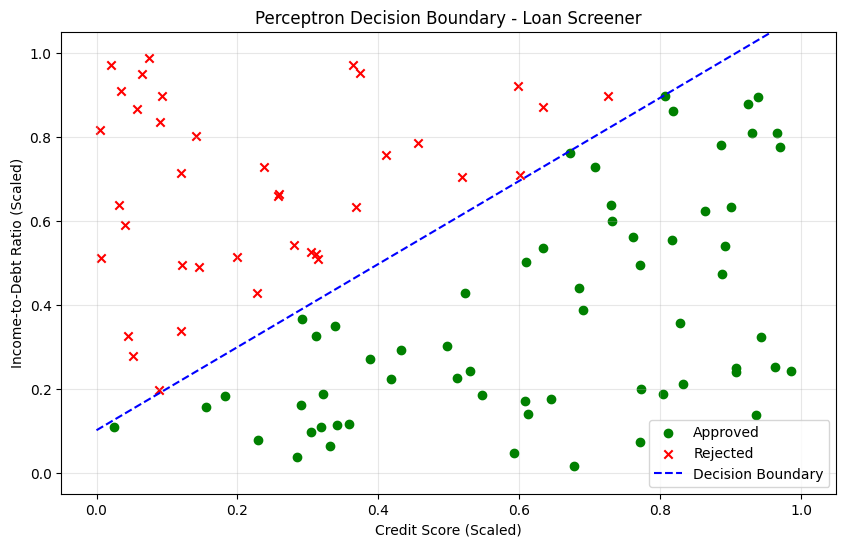

In [4]:
# Plot the learned decision boundary
plt.figure(figsize=(10, 6))

# Scatter points
plt.scatter(X_loan[y_loan == 1][:, 0], X_loan[y_loan == 1][:, 1], color='green', marker='o', label='Approved')
plt.scatter(X_loan[y_loan == 0][:, 0], X_loan[y_loan == 0][:, 1], color='red', marker='x', label='Rejected')

# Calculate and plot the boundary line: w1*x1 + w2*x2 + b = 0 => x2 = -(w1*x1 + b) / w2
w = perceptron_loan.weights
b = perceptron_loan.bias
x_boundary = np.linspace(0, 1, 100)
y_boundary = -(w[0] * x_boundary + b) / w[1]

plt.plot(x_boundary, y_boundary, color='blue', linestyle='--', label='Decision Boundary')
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.xlabel('Credit Score (Scaled)')
plt.ylabel('Income-to-Debt Ratio (Scaled)')
plt.title('Perceptron Decision Boundary - Loan Screener')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Task 4: Train on XOR Data and Show Failure to Converge

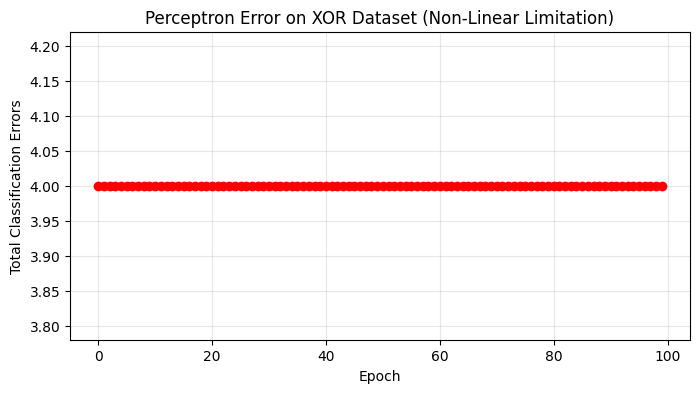

In [5]:
# Generate XOR Dataset
X_xor = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([0, 1, 1, 0])

# Train Perceptron on XOR
perceptron_xor = Perceptron(input_size=2, lr=0.1, epochs=100)
_, _, xor_error_hist = perceptron_xor.train(X_xor, y_xor)

# Plot the loss history to show failure to converge
plt.figure(figsize=(8, 4))
plt.plot(xor_error_hist, color='red', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Total Classification Errors')
plt.title('Perceptron Error on XOR Dataset (Non-Linear Limitation)')
plt.grid(True, alpha=0.3)
plt.show()

## Task 5: Compare Step, Sigmoid, and ReLU outputs for the same inputs

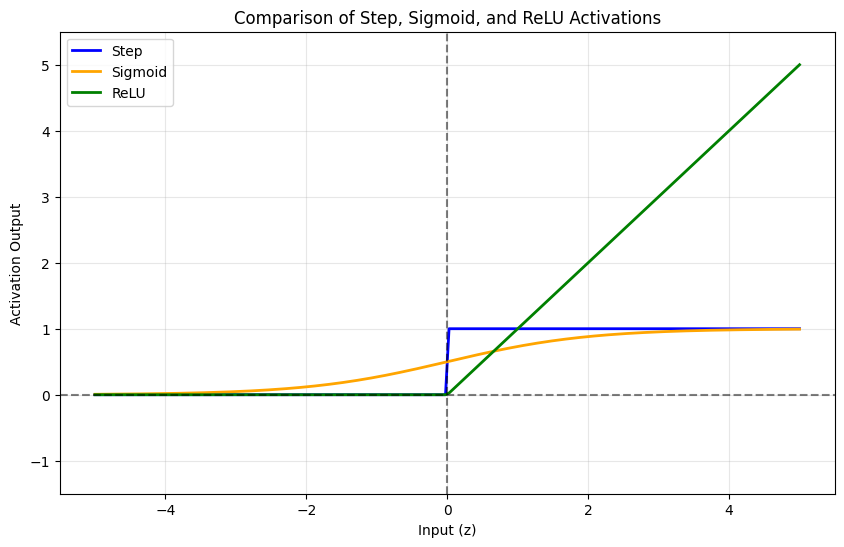

In [6]:
# Define activation functions
def sigmoid_activation(z):
    return 1 / (1 + np.exp(-z))

def relu_activation(z):
    return np.maximum(0, z)

# Input range for visualization
z_inputs = np.linspace(-5, 5, 200)

# Generate activations
y_step = step_activation(z_inputs)
y_sigmoid = sigmoid_activation(z_inputs)
y_relu = relu_activation(z_inputs)

# Plot comparison
plt.figure(figsize=(10, 6))
plt.plot(z_inputs, y_step, label='Step', color='blue', linewidth=2)
plt.plot(z_inputs, y_sigmoid, label='Sigmoid', color='orange', linewidth=2)
plt.plot(z_inputs, y_relu, label='ReLU', color='green', linewidth=2)
plt.axvline(0, color='black', linestyle='--', alpha=0.5)
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.ylim(-1.5, 5.5)
plt.title('Comparison of Step, Sigmoid, and ReLU Activations')
plt.xlabel('Input (z)')
plt.ylabel('Activation Output')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()